AutoGrad engine: Implements backpropagation (reverse-mode autodiff) over a dynamically built DAG and a small neural networks library on top of a pytorch-Like API

In [1]:
pip install micrograd

Note: you may need to restart the kernel to use updated packages.


## Manual Backpropagation

In [ ]:
from micrograd.engine import Value

a = Value(-2.0)
b = Value(3.0)
c = a + b
d = a * b + b**2
c += 1 + c + (-a)

d += d + 2 + (b+a).relu()
d += 3 + d + (b-a).relu()

e = c-d
f = e**2
g = f/ 2.0
g += 10.0/f

print(f"{g.data:.4f}")# prints the outcome of this forwrard pass
g.backward()
print(f"{a.grad:.4f}") # prints the gradient of a dg/da
print(f"{b.grad:.4f}") # prints the gradient of b dg/db

220.5227
251.9741
356.9633


In [36]:
!pip install matplotlib
!pip install numpy

In [122]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline



In [552]:
class Value:

    def __init__(self,data, _children={}, _op ='' , label=""):
        self.data = data
        self._grad = 0.0 #initializing in the backprop.
        self._backward = lambda : None 
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self,other), '+')

        def _backward():
            self._grad += 1.0 * out._grad
            other._grad += 1.0 * out._grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self,other), '*'   )
        def _backward():
            self._grad += other.data * out._grad
            other._grad += self.data * out._grad
        out._backward = _backward
        return out

    def __pow__(self, other):
        other = other if isinstance(other, (int,float)) else Value(other)
        out = Value(self.data ** other, (self,), f'**{other}' )
        def _backward():
            self._grad += other * (self.data **(other-1)) * out._grad
        out._backward = _backward
        return out 

    def backward(self):
        #topological order all of the children in the graph
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self._grad = 1.0
        for node in reversed(topo):
            node._backward()





    def __rmul__(self,other):
        return self * other

    def __truediv__(self,other):
        return self * other**-1

    
    def __neg__(self):
        return self * -1

    def __sub__(self,other): # -self
        return self + (-other)

    def __radd__(self,other):
        return self + other




    def tanh(self):
        #out = Value(math.exp(self.data), (self,), 'exp')
        x = self.data
        t = (math.exp(2*x)-1)/(math.exp(2*x)+1) #approximation of tanh function
        out = Value(t, (self,), 'tanh')

        def _backward():
            self._grad = (1-t**2) * out._grad
        out._backward = _backward
        return out


    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), 'exp')

        def _backward():
            self._grad += out.data * out._grad
        out._backward = _backward
        return out
     
    


 


a = Value(2.0,label='a')
b = Value(-3.0,label='b')
c = Value(10.0,label='c')

e = a*b ; e.label = "e"

d = e + c; d.label = "d"
f = Value(-2.0,label='f')
L = d*f; L.label = "L"


In [229]:
c-a

Value(data=8.0)

In [46]:
d._prev

{Value(data=-6.0), Value(data=10.0)}

In [47]:
d._op

'+'

In [156]:
from graphviz import Digraph

def trace(root):
    nodes,edges = set(),set()
    def build(v):
        if v not in nodes: 
            nodes.add(v)
            for child in v._prev:
                edges.add((child,v))
                build(child)
    build(root)
    return nodes,edges


def draw_dot(root):
    dot = Digraph(format='svg', graph_attr = {'rankdir': 'LR'}) # LR <- LEFT TO RİGHT
    nodes, edges = trace(root)
    for n in nodes: 
        uid = str(id(n))
        #for any node, create a new dot node with unique id
        dot.node(name = uid, label = "{%s | data %.4f | grad %.4f}" % (n.label, n.data, n._grad ), shape = 'record')
        if n._op: # if this node is a result of some operation, show the operation next to the node
            dot.node(name = uid + n._op, label = n._op)
            #and connect the operation node to the value node
            dot.edge(uid + n._op, uid)

    for n1,n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot

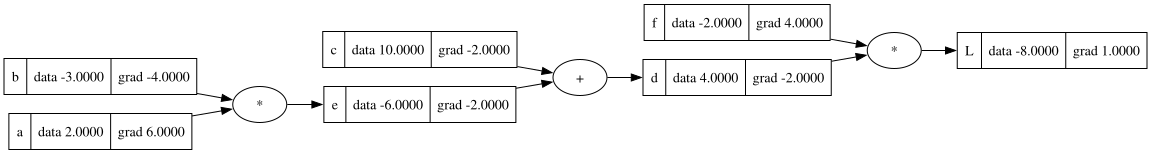

In [107]:
draw_dot(L)

In [106]:
# L = d*f , what is dL/dd = f , dL/df = d
#dL/dc ie. dd/dc = 1 , dd/dc = 1.0, de/da = -3.0, de/ db = 2.0
#dL/dc = dL/ dd * dd/dc = -2.0 * 1.0 = -2.0
#dL/de = dL/dd * dd/de = -2.0 * 1.0 = -2.0
#dL /da = dL/dd * dd/de * de/da = -2.0 * 1.0 * -3.0 = 6.0
#updating the gradients of L, f and d manually 
L._grad= 1.0
f._grad = 4.0
d._grad = -2.0
c._grad = -2.0
a._grad = 6.0
b._grad = -4.0
e._grad = -2.0

In [108]:
#one step of optimization

a.data += 0.01 * a._grad
b.data += 0.01 * b._grad
c.data += 0.01 * c._grad
f.data += 0.01 * f._grad


e = a * b 
d = e + c
L = d * f

print(L.data)




-7.286496


In [111]:
def lol():
    h = 0.001  

#first step
    a = Value(2.0,label='a')
    b = Value(-3.0,label='b')
    c = Value(10.0,label='c')
    e = a*b ; e.label = "e"
    d = e + c; d.label = "d"
    f = Value(-2.0,label='f')
    L = d*f; L.label = "L"
    L1 = L.data

#second step/ derv by a     
    a = Value(2.0 ,label='a')
    b = Value(-3.0 ,label='b')
    b.data += h
    c = Value(10.0,label='c')
    e = a*b ; e.label = "e"
    d = e + c   ; d.label = "d"
    #d.data += h
    f = Value(-2.0 ,label='f')
    L = d*f; L.label = "L"
    L2 = L.data 

    print((L2 - L1 )/ h)
#gating function for nor messig up the global scope   

lol() 


-3.9999999999995595


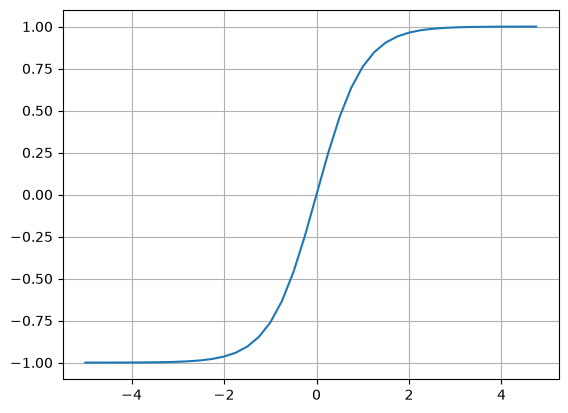

In [115]:
import numpy as np
import matplotlib.pyplot as plt
plt.plot(np.arange(-5,5,0.25), np.tanh(np.arange(-5,5,0.25))); plt.grid();
#capping smoothly around absolute 1

In [110]:
#todo: put this in a loop output is a list of gradients for each variable, and then we can plot them to see how the gradients change with respect to the input variables.

# Doing this on a Perceptron 

In [190]:
#Forward pass single neuron with 2 inpu 2 weights and bias, and tanh activation function

x1 = Value(2.0,label='x1')
x2 = Value(0.0,label='x2')
w1 = Value(-3.0,label='w1')
w2 = Value(1.0,label='w2')
b = Value(6.88,label='b')

x1w1 = x1*w1; x1w1.label = "x1w1"
x2w2 = x2*w2; x2w2.label = "x2w2"
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = "x1*w1+x2*w2"
n = x1w1x2w2 + b; n.label = "n"

o = n.tanh(); o.label = "o"


In [152]:
#manual backpropagation on perceptron 

o._grad = 1.0

#sech^2 = 1 -tanh^2(n)
n._grad = 1.0 - o.data**2

b._grad = 1.0 * n._grad
x1w1x2w2._grad = 1.0 * n._grad
x1w1._grad = 1.0 * n._grad
x2w2._grad = 1.0 * n._grad


x2._grad = w2.data * x2w2._grad
x1._grad = w1.data * x1w1._grad
w2._grad = x2.data * x2w2._grad
w1._grad = x1.data * x1w1._grad



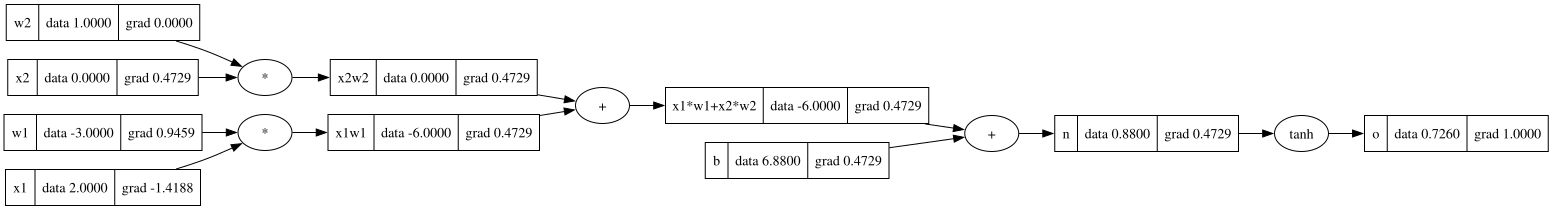

In [193]:
draw_dot(o)

In [192]:
o.backward()

In [186]:
o._grad = 1.0

topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)

build_topo(o)

for node in reversed(topo):
    node._backward()


In [183]:
#topological sort of the graph to get the order of backpropagation
#todo:neymiş bu ya
topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)

build_topo(o)
topo

[Value(data=-3.0),
 Value(data=2.0),
 Value(data=-6.0),
 Value(data=1.0),
 Value(data=0.0),
 Value(data=0.0),
 Value(data=-6.0),
 Value(data=6.88),
 Value(data=0.8799999999999999),
 Value(data=0.7259861751909268)]

In [177]:
o._grad = 1.0

o._backward()
n._backward()

x1w1x2w2._backward()
x1w1._backward()
x2w2._backward()


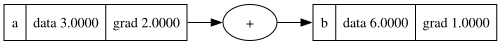

In [206]:
# the bug note

a = Value(3.0, label = 'a')
b = a + a ; b.label = 'b'
b.backward()
draw_dot(b)

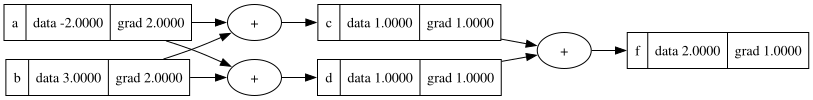

In [217]:
a = Value(-2.0, label = 'a')
b = Value(3.0, label= 'b')
c = a+b ; c.label = 'c'
d = a+b ; d.label = 'd'

f =c+d ; f.label = 'f'

f.backward()
draw_dot(f)

#adding gradients? 

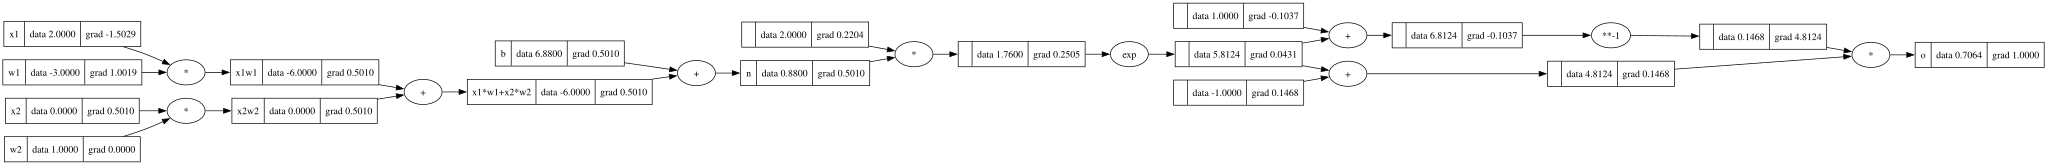

In [247]:

x1 = Value(2.0,label='x1')
x2 = Value(0.0,label='x2')
w1 = Value(-3.0,label='w1')
w2 = Value(1.0,label='w2')
b = Value(6.88,label='b')

x1w1 = x1*w1; x1w1.label = "x1w1"
x2w2 = x2*w2; x2w2.label = "x2w2"
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = "x1*w1+x2*w2"
n = x1w1x2w2 + b; n.label = "n"

#----
e = (2*n).exp()
o = (e-1) / (e+1)

#---
o.label = 'o'
o.backward()
draw_dot(o)



In [251]:
!pip install torch
import torch

In [258]:
x1 = torch.Tensor([2.0]).double()               ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()               ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()              ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()               ; w2.requires_grad = True
b = torch.Tensor([6.88]).double()               ; b.requires_grad = True

n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print("---")
print("x2", x2.grad.item())
print("w2", w2.grad.item())
print("x1", x1.grad.item())
print("w1", w1.grad.item())


0.7064193777288968
---
x2 0.5009716627691182
w2 0.0
x1 -1.5029149883073547
w1 1.0019433255382364


In [269]:
a = torch.Tensor([[1,2,3],[4,5,6]])
print(a)
print(f"dimension of a is {a.ndim}")
print(f"size of a is {a.shape}")
print(f"the usual datatype is {a.dtype} , therefore we are using the double() to get {a.double().dtype}")


tensor([[1., 2., 3.],
        [4., 5., 6.]])
dimension of a is 2
size of a is torch.Size([2, 3])
the usual datatype is torch.float32 , therefore we are using the double() to get torch.float64


In [270]:
import random

In [ ]:
## Primary vlasses 

class Neuron():
    def  __init__(self,nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))

    def __call__(self,x):
        #w * x + b
        act = sum((wi*xi for wi, xi in zip(self.w,x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

x = [2.0,3.0]
n = Neuron(2) # single neuron with two weights
n(x)

Value(data=0.02899726774195593)

In [463]:
class Layer:

    def __init__(self,nin,nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self,x):
        outs = [n(x)for n in self.neurons]
        return outs [0] if len(outs) == 1 else outs 

    def parameters(self):
        #return [p for neuron in self.neurons for p in neuron.parameters()]
        params = []
        for neuron in self.neurons: 
            ps = neuron.parameters()
            params.extend(ps)
        return params





In [380]:
x = [2.0,3.0]
n = Layer(2,3)
n(x)

[Value(data=0.9947799606441193),
 Value(data=0.5528171706713912),
 Value(data=0.06525743952100352)]

In [472]:
class MLP:

    def __init__(self,nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i],sz[i+1])for i in range(len(nouts))]

    def __call__(self,x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return[ p for layer in self.layers for p in layer.parameters()]

In [618]:
x = [2.0,3.0,-1]
n = MLP(3,[4,4,1])
n(x)

Value(data=-0.07688940912787556)

In [498]:
n.parameters()
num_params = len(n.parameters())
size_bytes = num_params * 8          # Python float = 64-bit = 8 bytes
print(f"{size_bytes / 1024**2:.6f} MB")
print(f"number of parameters: {len(n.parameters())}")

0.000313 MB
number of parameters: 41


In [623]:
xs = [
    [2.0,3.0,-1.0],
    [3.0,-1.0,0.5],
    [0.5,1.0,1.0],
    [1.0,1.0,-1.0]
]

ys = [1.0,-1.0,-1.0,1.0] #desired binary outcome

In [624]:
ypred = [n(x)for x in xs]
ypred
loss =sum((yout-ygt)**2 for ygt, yout in zip(ys,ypred))
loss
#calculating loss to go to the desired outcome, usin MSE
ypred

[Value(data=0.8760052589300757),
 Value(data=-0.96313882434629),
 Value(data=-0.8148842056613088),
 Value(data=0.8385330598718456)]

In [625]:
for k in range(30):
    #forward pass
    ypred = [n(x)for x in xs]
    loss =sum((yout-ygt)**2 for ygt, yout in zip(ys,ypred))
    #calculating loss to go to the desired outcome, usin MSE

    #backward pass 
    for p in n.parameters():
        p._grad = 0.0
    loss.backward()

    #updating parameters
    for p in n.parameters():
        p.data += -0.05 * p._grad

    print(k,loss.data)


0 0.07707287215156484
1 0.07208828880014218
2 0.06766916451097871
3 0.06372707671298476
4 0.06019083327978692
5 0.05700251513507343
6 0.054114553074089036
7 0.05148753859830017
8 0.04908856366868797
9 0.04688994693603407
10 0.04486824601158928
11 0.04300348396386326
12 0.04127853802532693
13 0.03967865237880609
14 0.03819104675931921
15 0.03680459970170734
16 0.035509590423695774
17 0.034297487125547046
18 0.033160772301372377
19 0.032092797764922375
20 0.031087663685266845
21 0.03014011714100983
22 0.029245466633103068
23 0.028399509716623833
24 0.027598471472794518
25 0.02683895198217836
26 0.0261178813067629
27 0.025432480763772608
28 0.024780229493585437
29 0.024158835500223907


In [626]:
ypred

[Value(data=0.9332041356645167),
 Value(data=-0.9792707082254789),
 Value(data=-0.8943699811585314),
 Value(data=0.9099458852135153)]